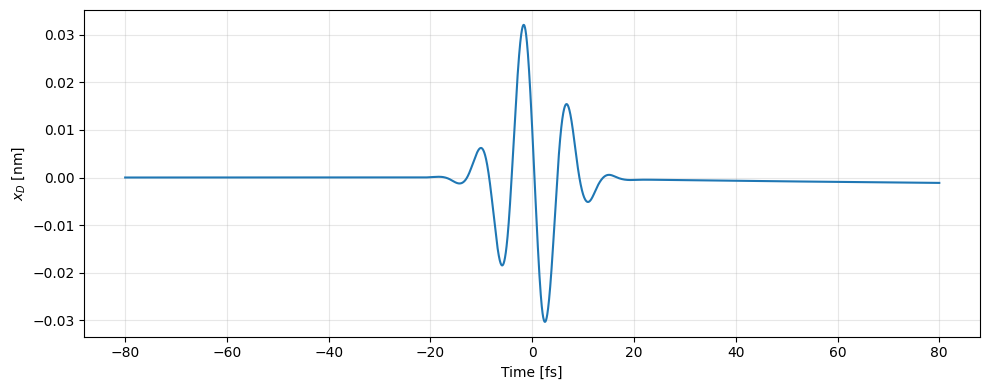

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# Physical constants
e = 1.602e-19          # C
mD = 9.109e-31         # kg

# Drude damping
gammaD = 0.1 / (20e-15)  # 1/s

# Driving pulse
E0 = 1e8               # V/m
w0 = 2 * np.pi * 1e8 / 800e-9   # rad/s, 800 nm

t0 = 0.0
fwhm = 10e-15          # intensity FWHM
sigma = fwhm / (2 * np.sqrt(np.log(2)))
phase_frac = 0.2

def E(t):
    envelope = np.exp(-(t - t0)**2 / (2 * sigma**2))
    return E0 * envelope * np.cos(w0 * (t - t0) + 2.0*np.pi*phase_frac)

# y = [x, v]
def equation(t, y):
    x, v = y
    return [v, -gammaD * v - (e / mD) * E(t)]

# Time grid
t = np.linspace(-80e-15, 80e-15, 5000)

sol = solve_ivp(
    equation,
    [t[0], t[-1]],
    y0=[0.0, 0.0],
    t_eval=t
)

x = sol.y[0]

# Plot
plt.figure(figsize=(10, 4))
plt.plot(t * 1e15, x * 1e9)

plt.xlabel("Time [fs]")
plt.ylabel(r"$x_D$ [nm]")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [3]:
# import numpy as np
# import matplotlib.pyplot as plt
# from scipy.integrate import solve_ivp

# # Normalized parameters
# e = 1.0
# m = 1.0
# gamma = 0.2

# # Driving pulse
# E0 = 1.0
# w0 = 2.0
# t0 = 0.0

# fwhm = 1
# sigma = fwhm / (2 * np.sqrt(np.log(2)))

# def E(t, phase_frac):
#     envelope = np.exp(-(t - t0)**2 / (2 * sigma**2))
#     return E0 * envelope * np.cos(
#         w0 * (t - t0) + 2 * np.pi * phase_frac
#     )

# def equation(t, y, phase_frac):
#     x, v = y
#     return [
#         v,
#         -gamma * v - (e / m) * E(t, phase_frac)
#     ]

# # Time grid
# t = np.linspace(-6, 6, 3000)

# # Scan phase
# phase_fracs = np.linspace(0, 1, 100)
# x_final = []

# for phase_frac in phase_fracs:

#     sol = solve_ivp(
#         equation,
#         [t[0], t[-1]],
#         y0=[0.0, 0.0],
#         t_eval=t,
#         args=(phase_frac,),
#         rtol=1e-9,
#         atol=1e-11
#     )

#     x_final.append(sol.y[0, -1])

# x_final = np.array(x_final)

# # Plot
# plt.figure(figsize=(10, 4))

# plt.plot(phase_fracs, x_final, linewidth=2)

# plt.xlabel(r"Phase fraction $\phi/(2\pi)$")
# plt.ylabel(r"Final position $x$")

# plt.grid(alpha=0.3)
# plt.tight_layout()
# plt.show()